# Thermo-optic phase shifter

A thermo-optic phase shifter is a TiN heater over a silicon waveguide.

**Question.** A titanium nitride strip, 2 µm wide and 320 µm long, runs 2 µm above a
500 × 220 nm silicon waveguide buried in oxide. A current through the strip heats the
oxide and the silicon, and silicon's index rises with temperature ($dn/dT = 1.86 \times 10^{-4}$
per kelvin at 1.55 µm). How much electrical power shifts the guided light's phase by
$\pi$? How much of that shift leaks into a second waveguide 10 µm away? And how fast does
the phase follow when the current switches on and off?

The device is the TiN phase shifter of Jacques et al., *Optics Express* **27**, 10456
(2019), simulated there in a 40 × 18 µm cross-section. Its published numbers are the
check at the end of this page.

The chain from current to phase has four steps, each one call:

1. {py:class}`gfem.DCConduction`: the current flows along the heater; its resistance
   per length.
2. {py:func}`gfem.joule_heating`: the heat that current dissipates in the heater.
3. {py:class}`gfem.SteadyThermal` (or {py:class}`gfem.TransientThermal` over time):
   the temperature it raises.
4. {py:func}`gfem.thermo_optic_shift`: the change of the guided mode's effective index,
   and the phase per length.

**Assumptions.**

- **A cross-section.** Nothing varies along the waveguide: the 320 µm heater is long
  next to the section's thermal spreading length (a few µm), so the heat flows
  sideways and down, not along the guide. Every quantity is per metre of guide; the
  heater's length only turns per-length values into the device's totals.
- **The stack.** From the bottom up: 13.14 µm of silicon substrate, a 2 µm buried
  oxide, the silicon core on it, then oxide up to 2.86 µm above the core's base. The
  heater sits 2 µm above the core (its base at 2.22 µm) and is 0.14 µm thick. The
  paper withholds the heater's thickness and the oxide over it; 0.14 µm and 0.5 µm
  are assumptions (see Limits).
- **Boundaries.** The bottom of the substrate is held at 300 K, the heat sink. The top
  of the oxide loses heat to air at 300 K with $h = 10$ W/m²/K. The sides, 20 µm from
  the core, are insulated.
- **Constant, linear materials.** Thermal conductivity $k$, mass density $\rho$ and specific
  heat $c_p$ take the paper's values (the core's $k$ is the thin-film value, 90 W/m/K,
  not bulk silicon's 148). Nothing depends on temperature except the optical index,
  to first order in the temperature rise. The TiN conductivity is 2.3 × 10⁶ S/m.
- **The optical mode is the fundamental TE mode at 1.55 µm**, solved on a window
  around each core (its 0.5 × 0.22 µm rectangle grown by 1.5 µm sideways and 1 µm up
  and down), with the rest of the section left out of the optical solve.

**Conventions.** SI units: the mesh file is in µm and gfem converts it to metres.
Temperatures are absolute, in kelvin; the *rise* is the temperature minus the
temperature with the heater off. On a cross-section, powers and resistances are per
metre of guide. The thermo-optic phase is a delay: positive for a positive $dn/dT$ and
a positive rise. A transmission's argument moves by minus it. See
{py:mod}`gfem.conventions`.

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy.constants import c

import gfem

um = 1e-6
WAVELENGTH = 1.55 * um
F0 = c / WAVELENGTH  # 193.4 THz
LENGTH = 320 * um  # the heater's length along the guide
T_ROOM = 300.0  # K
tic = time.perf_counter()

## The section

The mesh is a triangulated cross-section in the $(x, y)$ plane, $y$ up, $y = 0$ at the top
of the buried oxide. Its regions are `"substrate"`, `"box"`, `"cladding"`, `"core"`,
`"neighbour"` (the second waveguide, centred at $x = 10$ µm), `"heater"`, and each
core's optical window, `"window"` and `"neighbour_window"` (oxide). Its named edges
are `"bottom"` (the sink) and `"top"` (the oxide's top). The triangles are 30 nm on
the cores' edges, 35 nm on the heater's, at most 100 nm in the windows, and grow to
2 µm in the substrate. The notebook reads {download}`data/heater_w2.msh`, built by
`tools/heater_section_mesh.py`.

{py:meth}`gfem.Mesh.from_gmsh_cross_section` reads the section as a slab one
element thick along z: the guide's direction. Its two end faces are the surfaces
`"front"` and `"back"`. The current flows from one to the other, and the optical
mode is solved on `"front"`.

The materials carry all three physics at once: `eps_r` for the optical solve,
`thermal_conductivity`, `mass_density` and `specific_heat` for the thermal ones,
`conductivity` for the current, and `thermo_optic_coefficient` ($dn/dT$) where the
index moves with temperature.

In [2]:
OXIDE = gfem.Material(
    eps_r=1.444**2,
    thermal_conductivity=1.38,  # W/m/K
    mass_density=2203.0,  # kg/m^3
    specific_heat=709.0,  # J/kg/K
    thermo_optic_coefficient=1e-5,  # 1/K
    name="oxide",
)
SILICON_FILM = gfem.Material(
    eps_r=3.4777**2,
    thermal_conductivity=90.0,
    mass_density=2330.0,
    specific_heat=711.0,
    thermo_optic_coefficient=1.86e-4,
    name="silicon film",
)
SUBSTRATE = gfem.Material(
    thermal_conductivity=148.0, mass_density=2330.0, specific_heat=711.0
)
TIN = gfem.Material(
    thermal_conductivity=28.0,
    mass_density=5240.0,
    specific_heat=598.0,
    conductivity=2.3e6,  # S/m
    name="TiN",
)
MATERIALS = {
    "substrate": SUBSTRATE,
    "box": OXIDE,
    "cladding": OXIDE,
    "window": OXIDE,
    "neighbour_window": OXIDE,
    "core": SILICON_FILM,
    "neighbour": SILICON_FILM,
    "heater": TIN,
}
BOUNDARIES = [
    gfem.FixedTemperature("bottom", temperature=T_ROOM),
    gfem.Convection("top", coefficient=10.0, ambient=T_ROOM),
]

One mesh, two models. Both solve the same heat and current; they differ in which
regions the optical solve keeps. `excluded={"em": [...]}` leaves regions out of the
electromagnetic solves only: the substrate and the heater still conduct heat, and the
heater still carries current. The first model keeps the core and its window, so its
wave port's first mode is the core's guided mode; the second keeps the neighbour and
its window.

In [3]:
def models(path):
    # The section's two models: optics on the core's window, and on the neighbour's.
    mesh = gfem.Mesh.from_gmsh_cross_section(Path(path))
    thermal_only = ["substrate", "box", "cladding", "heater"]
    core = gfem.Model(
        mesh,
        materials=MATERIALS,
        boundaries=BOUNDARIES,
        ports=[gfem.WavePort("core", "front")],
        excluded={"em": [*thermal_only, "neighbour", "neighbour_window"]},
    )
    neighbour = core.replace(
        ports=[gfem.WavePort("neighbour", "front")],
        excluded={"em": [*thermal_only, "core", "window"]},
    )
    return core, neighbour


model, neighbour_model = models("data/heater_w2.msh")
model

Model(Mesh(9268 nodes, 27519 tetrahedra, volumes=['core', 'neighbour', 'heater', 'window', 'neighbour_window', 'box', 'cladding', 'substrate'], surfaces=['bottom', 'top', 'front', 'back'], length_unit='um', section_thickness=2.118e-07 m)
  materials:
    core: Material(eps_r=12.09439729, thermal_conductivity=90.0, mass_density=2330.0, specific_heat=711.0, thermo_optic_coefficient=0.000186, name='silicon film')
    neighbour: Material(eps_r=12.09439729, thermal_conductivity=90.0, mass_density=2330.0, specific_heat=711.0, thermo_optic_coefficient=0.000186, name='silicon film')
    heater: Material(conductivity=2300000.0, thermal_conductivity=28.0, mass_density=5240.0, specific_heat=598.0, name='TiN')
    window: Material(eps_r=2.085136, thermal_conductivity=1.38, mass_density=2203.0, specific_heat=709.0, thermo_optic_coefficient=1e-05, name='oxide')
    neighbour_window: Material(eps_r=2.085136, thermal_conductivity=1.38, mass_density=2203.0, specific_heat=709.0, thermo_optic_coefficient

## Resistance and P_π

**The resistance.** {py:class}`gfem.DCConduction` holds the heater's `"front"` face
at 1 V against its `"back"` face and solves for the current. Only the heater conducts
(it is the one material with a `conductivity`). On a cross-section the result is per
metre of guide: `resistance_per_length` is $1/(\sigma A)$ for a uniform strip of area $A$.

**The heat.** {py:func}`gfem.joule_heating` turns the conduction result into a heat
source for any drive, without a new solve. On a cross-section it takes the power per
metre of heater, or the current through it.

**$P_\pi$.** The rise is linear in the power, and the phase is linear in the rise, so one
steady solve at 1 W/m gives the phase per watt. `thermo_optic_shift` solves the core's
mode once and weighs each element's rise by the mode's intensity there:

$$
\Delta n_\mathrm{eff} = \frac{c \varepsilon_0}{4} \sum_e 2 n_e \left(\frac{dn}{dT}\right)_e \Delta T_e \int_e |E|^2 \, dA,
$$

with the mode at 1 W, and the phase per length is $\varphi' = k_0 \Delta n_\mathrm{eff}$. A heater of length $L$ dissipating $P$ has $P' = P / L$
per metre and gives the phase $\varphi = \varphi' L$, so $\pi$ needs

$$
P_\pi = \pi P' / \varphi',
$$

the same for any length: a longer heater spreads the same power thinner.

In [4]:
def p_pi_of(model):
    # The conduction result, the steady solve at 1 W/m, the shift and P_pi (W).
    dc = gfem.solve(model, gfem.DCConduction({"heater": "front"}, ground="back"))
    unit = gfem.solve(
        model, gfem.SteadyThermal(gfem.joule_heating(dc, power_per_length=1.0))
    )
    shift = gfem.thermo_optic_shift(model, unit.rise, port="core", frequency=F0)
    p_pi = np.pi * unit.power_per_length / shift.phase_per_length
    return dc, unit, shift, float(p_pi)


dc, unit, shift, p_pi = p_pi_of(model)
resistance = float(dc.resistance_per_length[0, 0]) * LENGTH
current_pi = np.sqrt(p_pi / resistance)
print(shift)
print(f"heater resistance over {LENGTH / um:.0f} um: {resistance:.1f} ohm")
per_watt = float(shift.phase_per_length / unit.power_per_length)
print(f"phase per watt: {per_watt:.1f} rad/W")
print(f"P_pi = {1e3 * p_pi:.2f} mW at {1e3 * current_pi:.2f} mA")
print(f"voltage across the heater: {current_pi * resistance:.2f} V")

ThermoOpticShift(port 'core', mode 1, 1.93414e+14 Hz, n_eff 2.447236, delta_n_eff 3.43746e-05, phase_per_length 139.343 rad/m)
heater resistance over 320 um: 496.9 ohm
phase per watt: 139.3 rad/W
P_pi = 22.55 mW at 6.74 mA
voltage across the heater: 3.35 V


$P_\pi$ is 22.55 mW: 6.74 mA through the 496.9 Ω strip, 3.35 V. The strip's resistance
is plain geometry, 320 µm / (2.3 × 10⁶ S/m × 2 µm × 0.14 µm) = 496.9 Ω.

The temperature at $P_\pi$, driven by that current: `joule_heating(dc, current=...)` takes
the current through the heater, the same number as in the device. The heater rises by
31.5 K and the core by 12.1 K: the 2 µm of oxide between them ($k = 1.38$ W/m/K) holds
most of the drop, and the buried oxide below the core the rest, down to the silicon
substrate ($k = 148$ W/m/K), which stays within a fraction of a kelvin of the sink.

A sanity limit: if only the core's index moved, $\pi$ would need $\Delta n_\mathrm{eff} L = \lambda/2$, a core
rise of $\lambda / (2 L \, dn/dT) = 13.0$ K. The core rises 12.1 K, within 10 % of that: part of
the mode runs in the oxide around the core, which is warm too and adds its own, smaller
$dn/dT$.

In [5]:
heat_pi = gfem.joule_heating(dc, current=current_pi)
steady = gfem.solve(model, gfem.SteadyThermal(heat_pi))
print(heat_pi)
print(f"power per length: {float(steady.power_per_length):.2f} W/m = P_pi / L")
core_rise = float(gfem.region_mean(steady.rise, "core"))
heater_rise = float(gfem.region_mean(steady.rise, "heater"))
print(f"mean rise: core {core_rise:.2f} K, heater {heater_rise:.2f} K")

HeatSource(joule, regions=['heater'], total 70.4553 W/m)
power per length: 70.46 W/m = P_pi / L
mean rise: core 12.06 K, heater 31.47 K


The section at $P_\pi$: the temperature (left; the dashed box is the core's optical
window) and the core's guided mode $|E|$ in its window (right). The mode sits in the
core and decays well inside the window. Its overlap with the warm core is what
the phase measures.

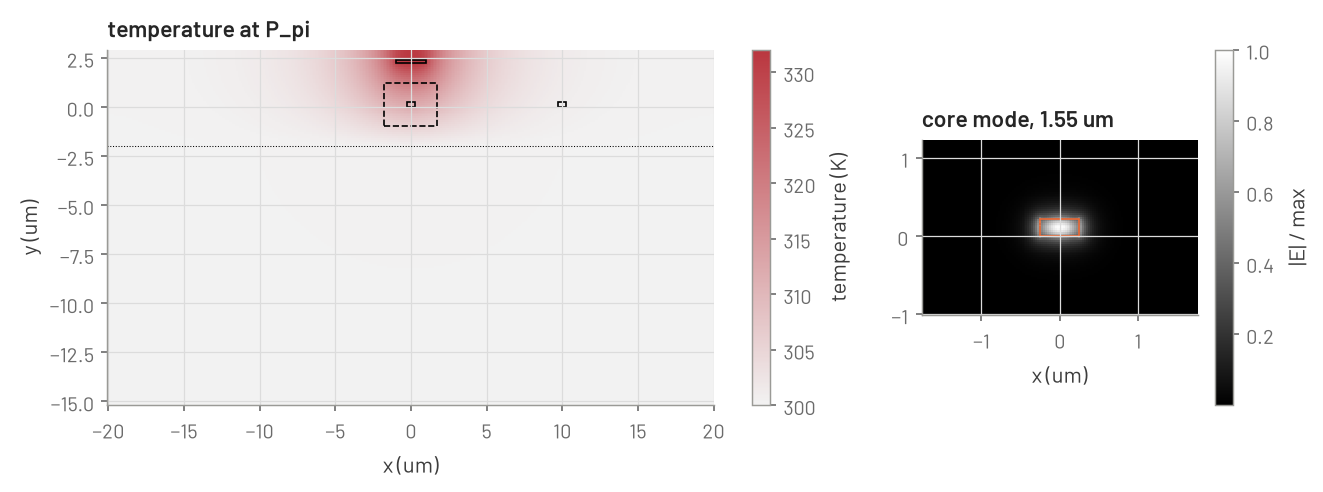

In [6]:
def grid(x, y, z):
    # The points of the grid x by y (m), at depth z along the guide, row by row.
    X, Y = np.meshgrid(x, y)
    return np.column_stack([X.ravel(), Y.ravel(), np.full(X.size, z)])


slab = model.mesh.section_thickness
x = np.linspace(-20, 20, 401) * um
y = np.linspace(-15.14, 2.86, 181) * um
temperature = np.asarray(steady.temperature.at(grid(x, y, slab / 2)))
temperature = temperature.reshape(y.size, x.size)

mode = gfem.solve(model, gfem.PortMode("core", F0))
xw = np.linspace(-1.75, 1.75, 141) * um
yw = np.linspace(-1.0, 1.22, 91) * um
e_mode = np.asarray(mode.e_field.at(grid(xw, yw, 0.0)))[0]  # (points, 3), V/m
e = np.linalg.norm(e_mode, axis=-1).reshape(yw.size, xw.size)

fig, (ax_t, ax_e) = plt.subplots(1, 2, figsize=(9, 3.4), width_ratios=(2.2, 1))
image = ax_t.pcolormesh(x / um, y / um, temperature, cmap="gfem_sensitivity")
fig.colorbar(image, ax=ax_t, label="temperature (K)")
for x0, y0, w, h, style in (
    (-1.0, 2.22, 2.0, 0.14, "-"),  # heater
    (-0.25, 0.0, 0.5, 0.22, "-"),  # core
    (9.75, 0.0, 0.5, 0.22, "-"),  # neighbour
    (-1.75, -1.0, 3.5, 2.22, "--"),  # the core's optical window
):
    ax_t.add_patch(plt.Rectangle((x0, y0), w, h, fill=False, ec="k", ls=style, lw=0.8))
ax_t.axhline(-2.0, color="k", lw=0.5, ls=":")
ax_t.set_xlabel("x (um)")
ax_t.set_ylabel("y (um)")
ax_t.set_title("temperature at P_pi")
image = ax_e.pcolormesh(xw / um, yw / um, e / e.max(), cmap="gray")
fig.colorbar(image, ax=ax_e, label="|E| / max")
ax_e.add_patch(plt.Rectangle((-0.25, 0.0), 0.5, 0.22, fill=False, ec="C1", lw=0.8))
ax_e.set_aspect("equal")
ax_e.set_xlabel("x (um)")
ax_e.set_title("core mode, 1.55 um")
fig.tight_layout();

## Where the heat goes

In steady state every watt the heater dissipates leaves the section: down into the
sink, or up through the top into the air. Nothing leaves through the insulated sides.
`gfem.heat_flow_per_length` gives the heat leaving through the sink and through the
top, and the heat crossing a horizontal cut 3.14 µm above the sink, out of the
elements above it. They must add up to the Joule power per length. All three are
read from the discrete heat balance of the solved temperature, so they close to
round-off.

Almost all of it goes down: the air takes 3 × 10⁻⁵ of the power. No heat is made
below the cut, so the heat crossing it is the sink's.

In [7]:
joule = float(steady.power_per_length)
sink = float(gfem.heat_flow_per_length(steady, "bottom", model=model))
up = float(gfem.heat_flow_per_length(steady, "top", model=model))
# out of the elements above y = -12 um, across the cut 3.14 um above the sink
down = float(
    gfem.heat_flow_per_length(steady, lambda c: c[:, 1] > -12.0 * um, model=model)
)
balance = abs(sink + up - joule) / joule
print(f"Joule power:        {joule:.4f} W/m")
print(f"down into the sink: {sink:.4f} W/m")
print(f"up into the air:    {up:.2e} W/m")
print(f"balance: |sink + up - Joule| / Joule = {balance:.1e}")
print(f"across the cut, minus the sink: {down - sink:.1e} W/m")

Joule power:        70.4553 W/m
down into the sink: 70.4531 W/m
up into the air:    2.23e-03 W/m
balance: |sink + up - Joule| / Joule = 1.3e-11
across the cut, minus the sink: 9.1e-10 W/m


## Thermal crosstalk

The heat spreads sideways too. A second waveguide 10 µm away warms up and its phase
moves: thermal crosstalk. The same rise, read through the neighbour's own optical
window, gives its phase per length. Its ratio to the heated core's is the crosstalk,
the same at every power.

In [8]:
neighbour_shift = gfem.thermo_optic_shift(
    neighbour_model, unit.rise, port="neighbour", frequency=F0
)
crosstalk = float(neighbour_shift.phase_per_length / shift.phase_per_length)
neighbour_rise = float(gfem.region_mean(steady.rise, "neighbour"))
print(f"neighbour's mean rise at P_pi: {neighbour_rise:.2f} K")
print(f"crosstalk: {crosstalk:.4f}")
print(f"neighbour's phase when the core has pi: {crosstalk * np.pi:.3f} rad")

neighbour's mean rise at P_pi: 0.95 K
crosstalk: 0.0787
neighbour's phase when the core has pi: 0.247 rad


At $P_\pi$ the neighbour turns by 0.247 rad, 7.9 % of the core's $\pi$: its mean rise is
0.95 K against the core's 12.1 K. Most of the heat goes straight down through the
buried oxide; what reaches 10 µm sideways has spread through the oxide and the top of
the substrate.

## Step response

{py:class}`gfem.TransientThermal` follows the temperature in time: the heater switches
on at $P_\pi$ at $t = 0$ and off at 80 µs, and the run ends at 160 µs, in 640 steps of
0.25 µs. Each shift's `trace()` records the phase per length at every step, at the
cost of a dot product: the mode stays the one solved above, and only the rise changes.

The phase rises towards $\pi$ and falls back to 0. The time scale is the oxide's: heat
diffuses through about 2 µm of it to the core, and through the buried oxide to the
substrate.

In [9]:
T_OFF, DURATION, STEPS = 80e-6, 160e-6, 640  # s, s, steps of 0.25 us
step = gfem.TransientThermal(
    heat_pi,
    duration=DURATION,
    steps=STEPS,
    waveform=[(0.0, 1.0), (T_OFF, 0.0)],  # on at 0, off at 80 us
    traces={"core": shift.trace(), "neighbour": neighbour_shift.trace()},
)
run = gfem.solve(model, step)
t = np.asarray(run.time)
phase = np.asarray(run.traces["core"]) * LENGTH  # rad
phase_neighbour = np.asarray(run.traces["neighbour"]) * LENGTH
phase_end = float(phase[-1])
print(f"phase at switch-off: {phase[t <= T_OFF][-1]:.4f} rad (pi = {np.pi:.4f})")
print(f"phase at the end:    {phase_end:.1e} rad")

phase at switch-off: 3.1406 rad (pi = 3.1416)
phase at the end:    9.9e-04 rad


The phase delay of each guide over time. Measured as the argument of a transmission,
the same curve reads downwards, from 0 to $-\pi$ and back. The neighbour's phase lags the
core's: its heat travels 10 µm sideways first.

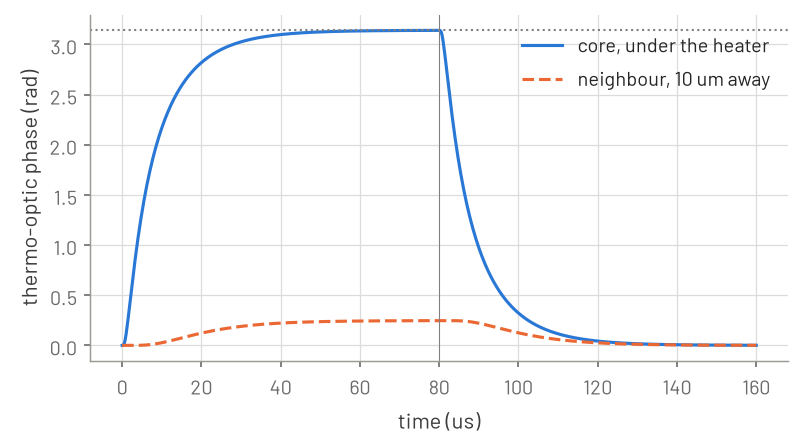

In [10]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(t / um, phase, label="core, under the heater")
ax.plot(t / um, phase_neighbour, label="neighbour, 10 um away")
ax.axhline(np.pi, color="gray", ls=":", lw=1)
ax.axvline(T_OFF / um, color="gray", lw=0.5)
ax.set_xlabel("time (us)")
ax.set_ylabel("thermo-optic phase (rad)")
ax.legend(loc="upper right");

Two numbers describe the response. {py:func}`gfem.rise_time` is the 10–90 % time, and
{py:func}`gfem.time_constant` the time to $1 - 1/e = 63.2$ % of the swing. Both
normalise each part of the trace to its first and last samples, so each part must end
settled: they warn ({py:class}`gfem.UnsettledTraceWarning`) when more than 1 % of the
swing is still to come. Here 80 µs is about nine time constants. The model is
linear, so the fall mirrors the rise.

In [11]:
rising, falling = t <= T_OFF, t >= T_OFF
tau = gfem.time_constant(t[rising], phase[rising], switch_times=(0.0,))
tau_fall = gfem.time_constant(t[falling], phase[falling], switch_times=(T_OFF,))
rise = gfem.rise_time(t[rising], phase[rising], switch_times=(0.0,))
print(f"time constant: rise {tau / um:.2f} us, fall {tau_fall / um:.2f} us")
print(f"10-90 % rise time: {rise / um:.2f} us")

time constant: rise 8.56 us, fall 8.56 us
10-90 % rise time: 18.56 us


The time constant is 8.56 µs, the 10–90 % rise time 18.56 µs. Their ratio, 2.17, is
close to a single exponential's $\ln 9 = 2.20$: one slow thermal mode dominates.

## Against the paper

Jacques et al. publish $P_\pi$ for two heater widths:

- 2.0 µm: simulated in the same 40 × 18 µm section, 21.4 mW in the abstract and
  23.9 mW in the text; we take the band 21.4–23.9 mW.
- 7.5 µm: the fabricated device, measured, 29.2–31.5 mW, with $1/e$ times of 3.7 µs
  (rise) and 7.2 µs (fall).

{download}`data/heater_w7p5.msh` is the same section with a 7.5 µm heater. The same
calls give its $P_\pi$ and, on 320 steps of 0.5 µs, its time constant.

In [12]:
wide, _ = models("data/heater_w7p5.msh")
dc_wide, unit_wide, shift_wide, p_pi_wide = p_pi_of(wide)
run_wide = gfem.solve(
    wide,
    gfem.TransientThermal(
        gfem.joule_heating(dc_wide, power_per_length=p_pi_wide / LENGTH),
        duration=DURATION,
        steps=320,
        waveform=[(0.0, 1.0), (T_OFF, 0.0)],
        traces={"core": shift_wide.trace()},
    ),
)
t_wide = np.asarray(run_wide.time)
on = t_wide <= T_OFF
tau_wide = gfem.time_constant(
    t_wide[on], np.asarray(run_wide.traces["core"])[on], switch_times=(0.0,)
)
print(f"{'heater':>7}  {'P_pi (mW)':>9}  {'published (mW)':>14}  time constant (us)")
print(f"{'2.0 um':>7}  {1e3 * p_pi:9.2f}       21.4-23.9  {tau / um:18.2f}")
print(f"{'7.5 um':>7}  {1e3 * p_pi_wide:9.2f}       29.2-31.5  {tau_wide / um:18.2f}")

 heater  P_pi (mW)  published (mW)  time constant (us)
 2.0 um      22.55       21.4-23.9                8.56
 7.5 um      30.09       29.2-31.5               10.07


Both $P_\pi$ fall inside the published bands: 22.55 mW at 2.0 µm and 30.09 mW at
7.5 µm. The wider heater spreads its heat over more oxide, so less of it reaches the
core: it needs a third more power.

The time constants do not match as well. At 7.5 µm the model gives 10.1 µs, above both
measured times (3.7 µs rising, 7.2 µs falling); the paper's simulated 5.6 µs (for a
2.5 µm heater) is also below our 8.56 µs at 2.0 µm. The model, not the solve, is the
likely cause: the two withheld thicknesses move the time constant (0.08 µm of oxide
over the heater instead of 0.5 µm shortens it by about 15 %), the measured device has
contacts and its own stack, and a rise faster than its fall points at physics outside
a linear model. Treat the time scale as an estimate to a few tens of percent.

## Limits

- **A cross-section is infinitely long.** Heat spreading along the guide, near the
  heater's ends and its contacts, is missing; so are the contacts' resistance and the
  heat they sink. The paper's total resistance, 0.54 kΩ with contacts, compares with
  the strip's 496.9 Ω here.
- **Withheld inputs.** The heater thickness (0.14 µm) and the oxide over it (0.5 µm)
  are assumptions. A thinner top oxide (0.08 µm) lowers $P_\pi$ by about 7 %.
- **Linear, constant materials.** No conductivity that depends on temperature, no
  radiation, no contact resistance. Above a few tens of kelvin of rise, $k(T)$ of
  silicon and oxide matter.
- **First order in the rise.** The phase is linear in the rise, exact to first order;
  at $P_\pi$ the second-order term changes $\Delta n_\mathrm{eff}$ by about 10⁻⁴ of itself.
- **The mesh and the domain.** The 40 × 18 µm domain is the paper's; its insulated
  sides and fixed sink depth move $P_\pi$ by a few percent if changed. That is part of the
  model, not a convergence parameter.

## Next

- {py:mod}`gfem.conventions`: temperatures, rises, per-length quantities and the sign
  of the thermo-optic phase.
- {doc}`../recipes/heater-temperature`, {doc}`../recipes/thermo-optic-phase` and
  {doc}`../recipes/thermal-step-response`: each step of this page as a task of its own.
- {doc}`../recipes/thermal-gradient`: the gradient of the phase with respect to the
  materials and the drive.
- {doc}`../recipes/prepare-a-mesh`: build a cross-section of your own device in gmsh.
- {doc}`bend`: optimize a waveguide's shape with gradients.

The numbers this page relies on, checked: the heat balance, the phase back at zero
after switch-off, $P_\pi$ inside the published bands at both widths and its value at
2.0 µm (22.55 mW), the heater's 496.9 Ω, the crosstalk (0.079) and the time constant
(8.56 µs, the same rising and falling).

In [13]:
p_pi_mw, p_pi_wide_mw = 1e3 * p_pi, 1e3 * p_pi_wide
np.testing.assert_array_less(balance, 1e-9)
np.testing.assert_array_less(abs(phase_end), 0.01)
np.testing.assert_array_less(21.4, p_pi_mw)
np.testing.assert_array_less(p_pi_mw, 23.9)
np.testing.assert_allclose(p_pi_mw, 22.55, atol=0.01)
np.testing.assert_array_less(29.2, p_pi_wide_mw)
np.testing.assert_array_less(p_pi_wide_mw, 31.5)
np.testing.assert_allclose(resistance, 496.9, atol=0.1)
np.testing.assert_allclose(crosstalk, 0.079, atol=0.001)
np.testing.assert_allclose(tau * 1e6, 8.56, atol=0.01)
np.testing.assert_allclose(tau_fall, tau, rtol=1e-3)
print(f"page run in {time.perf_counter() - tic:.0f} s")

page run in 180 s
